# European contract pricing with Tree

In [26]:
import numpy as np
from scipy.optimize import minimize, brentq
from collections.abc import Callable

## Create European contract payoff

In [27]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [28]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [29]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [30]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [31]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [32]:
price_tree[0][0]

0.05390000000000004

In [33]:
def balanced_tree_call_price(
    spot,
    strike,
    discount_factor,
    steps,
    spot_mult_up
):
    spot_mult_down = calcBalancedDownStep(
        spot_mult_up,
        discount_factor
    )

    spot_tree = create_spot_tree(
        spot,
        spot_mult_up,
        spot_mult_down,
        steps
    )

    price_tree = create_discounted_price_tree(
        spot_tree,
        discount_factor,
        strike,
        0
    )

    return price_tree[0][0]

In [34]:
def calibrate_up_step(
    target_price,
    spot,
    strike,
    discount_factor,
    steps,
    lower_bound=1.0001,
    upper_bound=2.0
):
    def root_function(spot_mult_up):
        model_price = balanced_tree_call_price(
            spot=spot,
            strike=strike,
            discount_factor=discount_factor,
            steps=steps,
            spot_mult_up=spot_mult_up
        )
        return model_price - target_price

    return brentq(
        root_function,
        lower_bound,
        upper_bound
    )

In [35]:
# calibrated_up = calibrate_up_step(
#     target_price=0.0539,
#     spot=1.0,
#     strike=1.0,
#     discount_factor=0.95,
#     steps=2
# )
#
# test_price = balanced_tree_call_price(
#     spot=1.0,
#     strike=1.0,
#     discount_factor=0.95,
#     steps=2,
#     spot_mult_up=calibrated_up
# )
#
# print("Calibrated up step:", calibrated_up)
# print("Tree price:", test_price)
# print("Target price:", 0.0539)
# print("Difference:", test_price - 0.0539)

In [36]:
for u in [1.0001, 1.01, 1.05, 1.1, 1.2, 1.5, 2.0]:
    price = balanced_tree_call_price(
        spot=1.0,
        strike=1.0,
        discount_factor=0.95,
        steps=2,
        spot_mult_up=u
    )
    print(u, price)

1.0001 0.09749999999999992
1.01 0.0974999999999999
1.05 0.09749999999999992
1.1 0.09749999999999992
1.2 0.13822499999999993
1.5 0.28203125
2.0 0.676875


In [37]:
calibrated_up = calibrate_up_step(
    target_price=0.138225,
    spot=1.0,
    strike=1.0,
    discount_factor=0.95,
    steps=2,
    lower_bound=1.1,
    upper_bound=1.5
)

calibrated_up

1.1999999999999982

In [38]:
calibrated_up = calibrate_up_step(
    target_price=0.138225,
    spot=1.0,
    strike=1.0,
    discount_factor=0.95,
    steps=2,
    lower_bound=1.1,
    upper_bound=1.5
)

print("Calibrated up step:", calibrated_up)

Calibrated up step: 1.1999999999999982


In [39]:
test_price = balanced_tree_call_price(
    spot=1.0,
    strike=1.0,
    discount_factor=0.95,
    steps=2,
    spot_mult_up=calibrated_up
)

print("Calibrated up step:", calibrated_up)
print("Tree price:", test_price)
print("Target price:", 0.0539)
print("Difference:", test_price - 0.0539)

Calibrated up step: 1.1999999999999982
Tree price: 0.13822499999999918
Target price: 0.0539
Difference: 0.08432499999999918


In [40]:
test_price = balanced_tree_call_price(
    spot=1.0,
    strike=1.0,
    discount_factor=0.95,
    steps=2,
    spot_mult_up=calibrated_up
)

print("Tree price:", test_price)
print("Target price:", 0.138225)
print("Difference:", test_price - 0.138225)

Tree price: 0.13822499999999918
Target price: 0.138225
Difference: -8.049116928532385e-16


In [41]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [42]:
step_values = [1, 2, 3, 5, 10]

calibrated_steps = []

for steps in step_values:
    step_discount_factor = 0.95 ** (1 / steps)

    u = calibrate_up_step(
        target_price=0.138225,
        spot=1.0,
        strike=1.0,
        discount_factor=step_discount_factor,
        steps=steps,
        lower_bound=1.0001,
        upper_bound=2.0
    )

    calibrated_steps.append(u)

    print(
        "steps =", steps,
        "discount factor =", step_discount_factor,
        "calibrated up =", u
    )

steps = 1 discount factor = 0.95 calibrated up = 1.291
steps = 2 discount factor = 0.9746794344808963 calibrated up = 1.2577758146824114
steps = 3 discount factor = 0.9830475724915585 calibrated up = 1.1720089150556032
steps = 5 discount factor = 0.9897937816869885 calibrated up = 1.1335470674147397
steps = 10 discount factor = 0.9948838031081763 calibrated up = 1.0978551642653214


In [43]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

0.146


In [44]:
for steps in [3, 5, 10]:
    print("steps =", steps)

    for u in [1.01, 1.05, 1.1, 1.2, 1.5, 2.0, 3.0]:
        price = balanced_tree_call_price(
            spot=1.0,
            strike=1.0,
            discount_factor=0.95,
            steps=steps,
            spot_mult_up=u
        )
        print("u =", u, "price =", price)

    print()

steps = 3
u = 1.01 price = 0.14262499999999984
u = 1.05 price = 0.14262499999999984
u = 1.1 price = 0.14262499999999986
u = 1.2 price = 0.17562649999999996
u = 1.5 price = 0.3708710937499997
u = 2.0 price = 0.7502031249999999
u = 3.0 price = 3.237125

steps = 5
u = 1.01 price = 0.22621906249999965
u = 1.05 price = 0.22621906249999965
u = 1.1 price = 0.22621906249999976
u = 1.2 price = 0.2591663154812498
u = 1.5 price = 0.46616835144042934
u = 2.0 price = 0.8323235742187498
u = 3.0 price = 10.9481028125

steps = 10
u = 1.01 price = 0.4012630607616203
u = 1.05 price = 0.40126306076162044
u = 1.1 price = 0.40126306076162055
u = 1.2 price = 0.42359466141009106
u = 1.5 price = 0.6446396344110379
u = 2.0 price = 0.9557530162561034
u = 3.0 price = 234.99518278372776



In [45]:
step_values = [1, 2, 3, 5, 10]

calibrated_steps = []

for steps in step_values:
    step_discount_factor = 0.95 ** (1 / steps)

    u = calibrate_up_step(
        target_price=0.138225,
        spot=1.0,
        strike=1.0,
        discount_factor=step_discount_factor,
        steps=steps,
        lower_bound=1.0001,
        upper_bound=2.0
    )

    calibrated_steps.append(u)

    print(
        "steps =", steps,
        "discount factor =", step_discount_factor,
        "calibrated up =", u
    )

steps = 1 discount factor = 0.95 calibrated up = 1.291
steps = 2 discount factor = 0.9746794344808963 calibrated up = 1.2577758146824114
steps = 3 discount factor = 0.9830475724915585 calibrated up = 1.1720089150556032
steps = 5 discount factor = 0.9897937816869885 calibrated up = 1.1335470674147397
steps = 10 discount factor = 0.9948838031081763 calibrated up = 1.0978551642653214


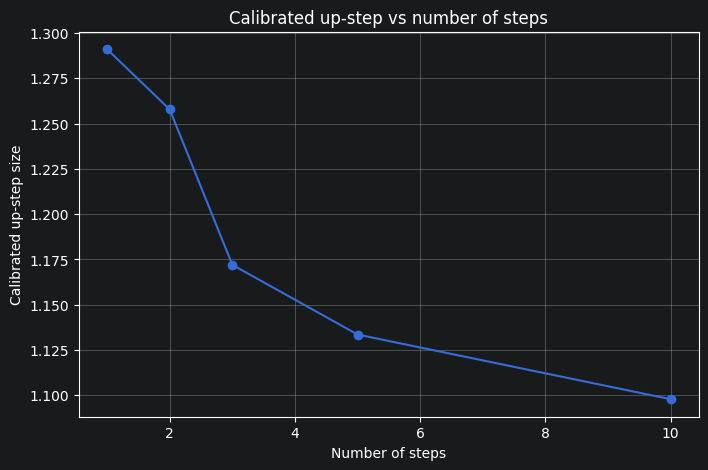

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(step_values, calibrated_steps, marker="o")

plt.xlabel("Number of steps")
plt.ylabel("Calibrated up-step size")
plt.title("Calibrated up-step vs number of steps")
plt.grid(True)

plt.show()

In [47]:
contracts = [
    {"strike": 0.9, "maturity": 0.5, "target_price": 0.18},
    {"strike": 1.0, "maturity": 1.0, "target_price": 0.138225},
    {"strike": 1.1, "maturity": 2.0, "target_price": 0.12},
]

contract_results = []

for contract in contracts:
    steps = 1
    step_discount_factor = 0.95 ** contract["maturity"]

    calibrated_u = calibrate_up_step(
        target_price=contract["target_price"],
        spot=1.0,
        strike=contract["strike"],
        discount_factor=step_discount_factor,
        steps=steps,
        lower_bound=1.0001,
        upper_bound=2.0
    )

    contract_results.append(calibrated_u)

    print(
        "strike =", contract["strike"],
        "maturity =", contract["maturity"],
        "calibrated up =", calibrated_u
    )

strike = 0.9 maturity = 0.5 calibrated up = 1.2693522067506555
strike = 1.0 maturity = 1.0 calibrated up = 1.291
strike = 1.1 maturity = 2.0 calibrated up = 1.3659279778393352


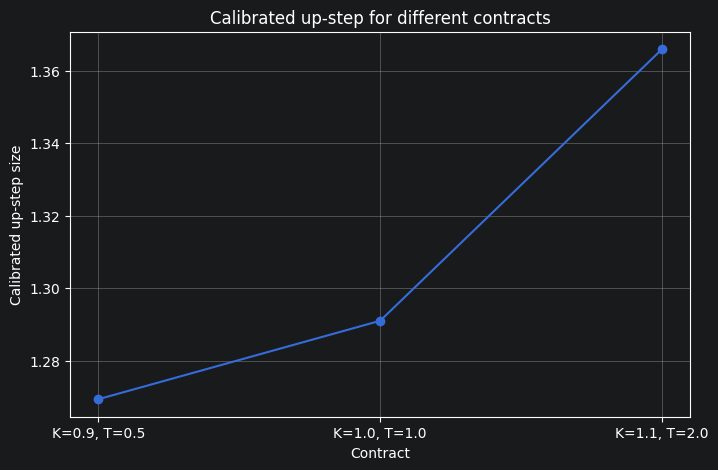

In [48]:
labels = [
    f"K={c['strike']}, T={c['maturity']}"
    for c in contracts
]

plt.figure(figsize=(8, 5))
plt.plot(labels, contract_results, marker="o")

plt.xlabel("Contract")
plt.ylabel("Calibrated up-step size")
plt.title("Calibrated up-step for different contracts")
plt.grid(True)

plt.show()

## Balanced Tree

In [49]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [50]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.645']]
price tree: [['0.095'], ['0.000', '0.190']]


## Delta is close to 0.5 for At The Money Forward option

In [51]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.296']]
price tree:


[['0.044'], ['0.000', '0.087']]

## Barrier options

In [52]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [53]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [54]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [55]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(np.float64(0.5), np.float64(0.5))
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## Q: How would you model continuous barrier better?